# Exploratory data analysis: UCI Heart Disease (4 hospitals)

**Goal:** understand the data well enough to decide how to clean it and what can safely be used as a feature.

The dataset combines patients referred for coronary angiography at four hospitals in the 1980s:
Cleveland Clinic, the Hungarian Institute of Cardiology (Budapest), University Hospitals Zurich/Basel and the VA Medical Center in Long Beach.
The outcome `num` is the angiographic result: 0 = less than 50% narrowing in every major vessel, 1-4 = disease.

Every decision made here is implemented in `src/cardiofed/data.py` (cleaning) and tested in `src/cardiofed/train.py` (feature ablation).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from cardiofed import config as C
from cardiofed.data import load_raw, clean

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
SITE_ORDER = list(C.HOSPITALS)
PALETTE = {"cleveland": "#1b2a41", "hungarian": "#2f7f7a", "switzerland": "#c8102e", "va": "#c98b2b"}

## 1. Load the raw files

The four `processed.*.data` files use `?` for missing values and have no header row.

In [2]:
raw = load_raw()
print(raw.shape)
raw.groupby("hospital").size().reindex(SITE_ORDER).rename("patients").to_frame()

(920, 15)


,patients
hospital,
cleveland,303
hungarian,294
switzerland,123
va,200


In [3]:
raw.head()

,hospital,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,cleveland,63.0,1,1,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0.0
1,cleveland,67.0,1,4,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2.0
2,cleveland,67.0,1,4,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1.0
3,cleveland,37.0,1,3,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0.0
4,cleveland,41.0,0,2,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0.0


In [4]:
raw.describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
age,920.0,53.5,9.4,28.0,47.0,54.0,60.0,77.0
sex,920.0,0.8,0.4,0.0,1.0,1.0,1.0,1.0
cp,920.0,3.2,0.9,1.0,3.0,4.0,4.0,4.0
trestbps,861.0,132.1,19.1,0.0,120.0,130.0,140.0,200.0
chol,890.0,199.1,110.8,0.0,175.0,223.0,268.0,603.0
fbs,830.0,0.2,0.4,0.0,0.0,0.0,0.0,1.0
restecg,918.0,0.6,0.8,0.0,0.0,0.0,1.0,2.0
thalach,865.0,137.5,25.9,60.0,120.0,140.0,157.0,202.0
exang,865.0,0.4,0.5,0.0,0.0,0.0,1.0,1.0
oldpeak,858.0,0.9,1.1,-2.6,0.0,0.5,1.5,6.2


The summary already shows two problems: **`chol` and `trestbps` have a minimum of 0**, which is impossible for a living patient,
and `ca`, `thal` and `slope` have far fewer non-missing values than the other columns.

## 2. Missing values, by hospital

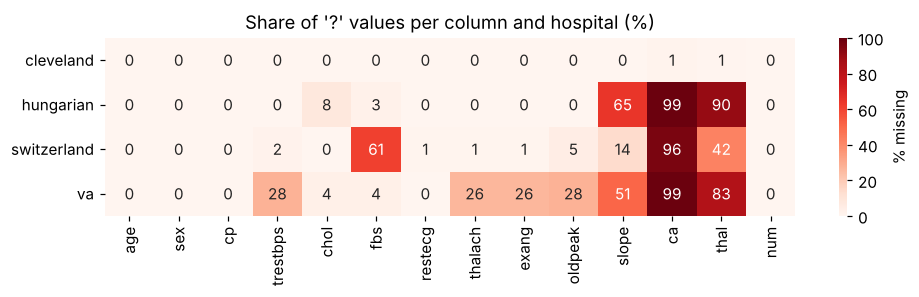

In [5]:
missing = raw.drop(columns=["hospital"]).isna().groupby(raw["hospital"]).mean().reindex(SITE_ORDER) * 100
fig, ax = plt.subplots(figsize=(9, 2.8))
sns.heatmap(missing, annot=True, fmt=".0f", cmap="Reds", cbar_kws={"label": "% missing"}, ax=ax, vmin=0, vmax=100)
ax.set(xlabel="", ylabel="", title="Share of '?' values per column and hospital (%)")
plt.tight_layout(); plt.show()

Missingness is **not random - it is a property of the hospital**:

* `ca` (vessels seen on fluoroscopy) exists almost only at Cleveland (99% missing elsewhere).
* `thal` (thallium scan) is missing for 90% of Budapest and 83% of VA patients.
* `slope` is missing for 65% of Budapest and 51% of VA patients.
* VA lacks about a quarter of its exercise-test values.

This matters because the hospitals have very different disease rates (next section). A model can use *which fields are blank* to work out the hospital, and from the hospital, the base rate.

## 3. Zeros that really mean 'not measured'

In [6]:
zeros = pd.DataFrame({c: (raw[c] == 0).groupby(raw["hospital"]).sum() for c in ["chol", "trestbps"]}).reindex(SITE_ORDER)
zeros["patients"] = raw.groupby("hospital").size()
zeros

,chol,trestbps,patients
hospital,,,
cleveland,0,0,303
hungarian,0,0,294
switzerland,123,0,123
va,49,1,200


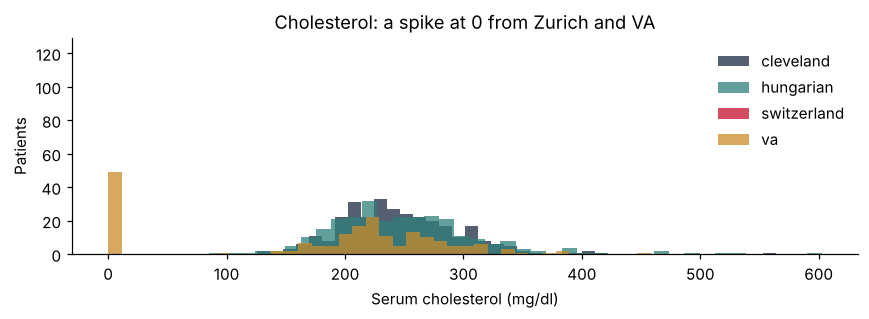

In [7]:
fig, ax = plt.subplots(figsize=(8, 3))
for s in SITE_ORDER:
    ax.hist(raw.loc[raw.hospital == s, "chol"].dropna(), bins=40, alpha=0.75, label=s, color=PALETTE[s])
ax.set(xlabel="Serum cholesterol (mg/dl)", ylabel="Patients", title="Cholesterol: a spike at 0 from Zurich and VA")
ax.legend(frameon=False); plt.tight_layout(); plt.show()

**All 123 Zurich patients and 49 VA patients have cholesterol = 0.** One VA patient has resting blood pressure 0.
These are missing-value codes, not measurements. Left as 0 they would distort every statistic and teach a model that
'cholesterol 0' predicts disease.

**Decision:** convert 0 to missing for `chol` and `trestbps`, and apply wide physiological range checks to every numeric column
(`config.VALID_RANGES`) so a future re-download can't sneak impossible values in.

## 4. Duplicates

In [8]:
dups = raw[raw.duplicated(keep=False)]
print(f"{raw.duplicated().sum()} exact duplicate rows")
dups

2 exact duplicate rows


,hospital,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
404,hungarian,49.0,0,2,110.0,NaN,0.0,0.0,160.0,0.0,0.0,NaN,NaN,NaN,0.0
405,hungarian,49.0,0,2,110.0,NaN,0.0,0.0,160.0,0.0,0.0,NaN,NaN,NaN,0.0
859,va,58.0,1,3,150.0,219.0,0.0,1.0,118.0,1.0,0.0,NaN,NaN,NaN,2.0
907,va,58.0,1,3,150.0,219.0,0.0,1.0,118.0,1.0,0.0,NaN,NaN,NaN,2.0


Two records appear twice (one in Budapest, one at VA), identical across all 14 attributes.
**Decision:** keep one copy. If a duplicate landed in both the training and the test set, the test score would be inflated.

## 5. Outliers

Now look at the numeric columns after replacing the zero-codes.

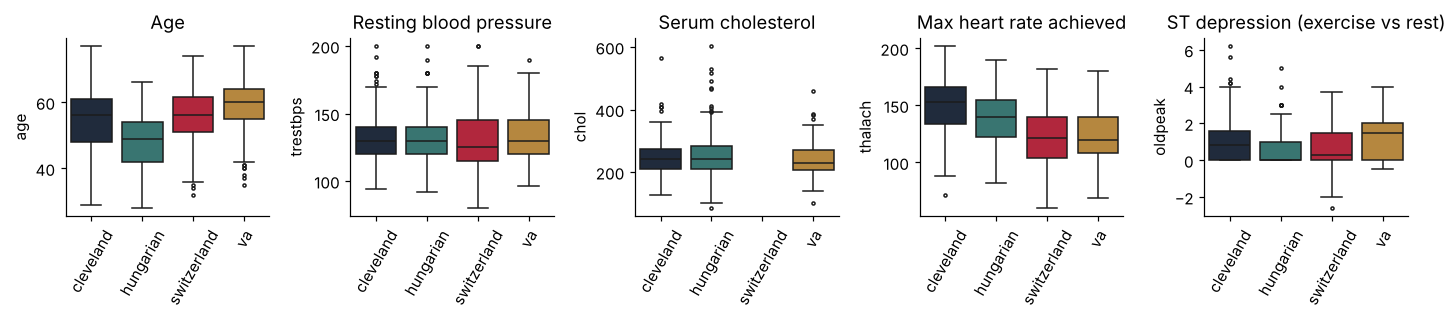

In [9]:
df, log = clean(raw)
num_cols = ["age", "trestbps", "chol", "thalach", "oldpeak"]
fig, axes = plt.subplots(1, 5, figsize=(13, 3))
for ax, c in zip(axes, num_cols):
    sns.boxplot(data=df, x="hospital", y=c, order=SITE_ORDER, hue="hospital", palette=PALETTE, ax=ax, fliersize=2, legend=False)
    ax.set(xlabel="", title=C.FEATURE_LABELS[c]); ax.tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.show()

In [10]:
rows = []
for c in num_cols:
    s = df[c].dropna()
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    out = s[(s < lo) | (s > hi)]
    rows.append({"column": c, "IQR low": lo, "IQR high": hi, "outliers": len(out),
                 "most extreme": out.loc[(out - s.median()).abs().idxmax()] if len(out) else None})
pd.DataFrame(rows).set_index("column").round(1)

,IQR low,IQR high,outliers,most extreme
column,,,,
age,27.5,79.5,0,NaN
trestbps,90.0,170.0,27,200.0
chol,109.5,377.5,23,603.0
thalach,64.5,212.5,2,60.0
oldpeak,-2.2,3.8,16,6.2


In [11]:
df.loc[df.chol > 450, ["hospital", "age", "sex", "chol", "num"]]

,hospital,age,sex,chol,num
152,cleveland,67.0,0,564.0,0.0
433,hungarian,53.0,0,468.0,0.0
499,hungarian,40.0,1,466.0,1.0
527,hungarian,32.0,1,529.0,1.0
545,hungarian,54.0,1,603.0,1.0
567,hungarian,53.0,1,518.0,1.0
583,hungarian,44.0,1,491.0,1.0
799,va,58.0,1,458.0,0.0


In [12]:
df.loc[df.oldpeak < 0, ["hospital", "age", "oldpeak", "num"]]

,hospital,age,oldpeak,num
602,switzerland,38.0,-1.1,0.0
608,switzerland,42.0,-1.5,1.0
613,switzerland,45.0,-0.1,0.0
614,switzerland,46.0,-2.6,1.0
628,switzerland,51.0,-0.7,2.0
652,switzerland,56.0,-2.0,2.0
654,switzerland,56.0,-1.0,1.0
655,switzerland,56.0,-1.0,2.0
690,switzerland,62.0,-0.8,1.0
693,switzerland,62.0,-0.5,1.0


The IQR rule flags a few dozen values, but they are **plausible extremes, not errors**:
cholesterol of 500-600 mg/dl occurs in familial hypercholesterolaemia, a resting systolic pressure of 200 mmHg is severe but real,
and negative `oldpeak` means ST *elevation* on exercise (rare but clinically meaningful; 11 of the 12 come from Zurich).

**Decisions:**
* Do **not** delete these patients. They are real people, and with only 918 rows each one matters.
* Tree models (XGBoost) only use the rank order of a value, so extremes can't pull them around.
* The linear baseline is sensitive to extremes, so its pipeline **winsorises** each numeric column to the 1st-99th percentile.
  The bounds are learned on the training fold only, so test data never shapes them.

## 6. The outcome

In [13]:
tab = pd.crosstab(df.hospital, df.num).reindex(SITE_ORDER)
tab["prevalence"] = (df.groupby("hospital")[C.TARGET].mean() * 100).round(1)
tab

num,0.0,1.0,2.0,3.0,4.0,prevalence
hospital,,,,,,
cleveland,164,55,36,35,13,45.9
hungarian,187,106,0,0,0,36.2
switzerland,8,48,32,30,5,93.5
va,51,56,40,42,10,74.4


Two findings:

1. **Disease rates differ enormously between hospitals:** 36% in Budapest, 46% in Cleveland, 74% at VA, 94% in Zurich.
   Any feature that reveals the hospital is therefore a proxy for the label.
2. **Budapest only recorded 0 or 1.** The other sites graded disease 1-4, so a Budapest "1" is not comparable with a Cleveland "1".
   **Decision:** the main target is binary (`num > 0`). The severity model (grade 1 / 2 / 3-4) is trained only on the three hospitals that graded.

## 7. Which features separate the classes?

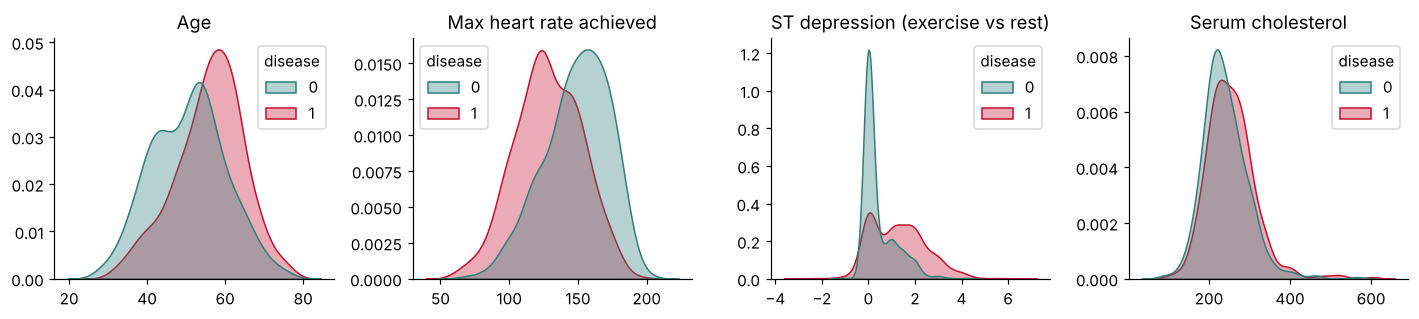

In [14]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3))
for ax, c in zip(axes, ["age", "thalach", "oldpeak", "chol"]):
    sns.kdeplot(data=df, x=c, hue=C.TARGET, common_norm=False, fill=True, alpha=.35, ax=ax,
                palette={0: "#2f7f7a", 1: "#c8102e"}, warn_singular=False)
    ax.set(title=C.FEATURE_LABELS[c], xlabel="", ylabel="")
    ax.get_legend().set_title("disease")
plt.tight_layout(); plt.show()

In [15]:
cp_names = {v: k.replace("_", " ") for k, v in C.CATEGORY_CODES["cp"].items()}
(df.assign(chest_pain=df.cp.map(cp_names)).groupby("chest_pain")[C.TARGET]
   .agg(patients="size", disease_rate="mean").sort_values("disease_rate").round(2))

,patients,disease_rate
chest_pain,,
atypical angina,173,0.14
non anginal pain,203,0.35
typical angina,46,0.43
asymptomatic,496,0.79


Exercise-test results (lower max heart rate, more ST depression) separate the classes clearly. Cholesterol barely does, which is a known quirk of this referral population.

**'Asymptomatic' patients have the highest disease rate (79%).** This looks backwards, but it is selection bias:
everyone here was sent for angiography, and a patient sent *without* chest pain was referred because of other strong evidence.
The model will learn this, and the web UI explains it next to the input.

## 8. Leakage checks

In [16]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score

feat = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg", "thalach", "exang", "oldpeak", "slope", "ca", "thal"]
mask = df[feat].isna().astype(int)
acc_all = cross_val_score(DecisionTreeClassifier(max_depth=4, random_state=0), mask, df.hospital, cv=5).mean()
acc_no_ca = cross_val_score(DecisionTreeClassifier(max_depth=4, random_state=0), mask.drop(columns=["ca", "thal"]), df.hospital, cv=5).mean()
print(f"Hospital predicted from the missing-value pattern alone: {acc_all:.0%} accuracy (majority guess {df.hospital.value_counts(normalize=True).max():.0%})")
print(f"... after dropping ca and thal: {acc_no_ca:.0%}")

Hospital predicted from the missing-value pattern alone: 84% accuracy (majority guess 33%)
... after dropping ca and thal: 74%


In [17]:
cle = df[df.hospital == "cleveland"]
pd.crosstab(cle.ca, cle[C.TARGET], normalize="index").round(2).rename(columns={0: "no disease", 1: "disease"})

has_disease,no disease,disease
ca,,
0.0,0.74,0.26
1.0,0.32,0.68
2.0,0.18,0.82
3.0,0.15,0.85


* From *which values are missing* alone, a shallow tree identifies the hospital most of the time. With disease rates from 36% to 94%, that is a back door to the label.
* `ca` is the number of major vessels seen on **fluoroscopy**, which is part of the same catheterisation procedure that defines the outcome.
  At Cleveland, 0 vessels means 26% disease and 3 vessels means 85%. It is close to target leakage, and in any case unavailable before the procedure.

**Decisions** (verified by the ablation in `train.py` / `reports/feature_selection.json`):
* Drop `ca` and `thal`: recorded at one site, partly part of the diagnosis, and mostly informative about *where* a patient was seen.
* Keep `slope`: recorded at three of the four sites, and central to reading a stress test.
* Don't let "missing" become a signal. With native NaN handling, leaving cholesterol blank raised predicted risk by about 10 points,
  because blank cholesterol mostly meant Zurich. CardioFed trains on randomly imputed values and averages over imputations at prediction time,
  which brings that shift to about 0 without hurting accuracy on unseen hospitals.

## 9. Cleaning summary

In [18]:
pd.DataFrame([{k: v for k, v in s.items() if k in ("step", "why", "rows_removed", "values_changed", "rows")} for s in log.steps]).fillna("")

,step,why,rows_removed,values_changed,rows
0,drop_exact_duplicates,identical records would leak between train and...,2.0,,
1,zero_to_missing_chol,chol = 0 is physiologically impossible (missin...,,172.0,
2,zero_to_missing_trestbps,trestbps = 0 is physiologically impossible (mi...,,1.0,
3,range_check_age,valid range 18..100,,0.0,
4,range_check_trestbps,valid range 60..250,,0.0,
5,range_check_chol,valid range 80..700,,0.0,
6,range_check_thalach,valid range 50..230,,0.0,
7,range_check_oldpeak,valid range -3.0..7.0,,0.0,
8,range_check_ca,valid range 0..3,,0.0,
9,flag_iqr_outliers,plausible extremes are real patients - flagged...,,,


In [19]:
print(f"{len(raw)} raw rows -> {len(df)} clean rows; {df[C.TARGET].mean():.1%} with disease")
C.DATA_PROCESSED.mkdir(parents=True, exist_ok=True)
df.to_csv(C.DATA_PROCESSED / "heart_clean.csv", index=False)

920 raw rows -> 918 clean rows; 55.3% with disease
